# 05 — DOI-Level Publication-Sampling Variability

This notebook is titled deliberately as publication-level sampling variability, not predictive uncertainty and not uncertainty quantification (UQ). It answers "if the literature corpus had sampled a different, similarly-sized set of publications, how much would the reported pooled metrics move?" — not "how confident should I be in any single prediction?" — and it doesn't separate epistemic from aleatoric uncertainty.

No model is retrained anywhere in this notebook. The out-of-fold predictions were fixed by Notebook 03, persisted to `data/modelling_results/notebook03_oof_predictions.csv`, and are only resampled here — whole DOI clusters, with replacement — the predictions themselves never change between bootstrap replicates.


## Imports

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "modelling" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from literature_pipeline.modelling import modelling_lib as ml

# NOTE: thin analysis layer over modelling_lib.py's bootstrap_metric_ci / bootstrap_metric_contrast.
# No bootstrap/resampling logic is duplicated here.

## Load the same persisted OOF artifact used by Notebook 04

No retraining, no dependence on Notebook 03/04's in-memory state.


In [2]:
OOF_ARTIFACT_PATH = PROJECT_ROOT / "data" / "modelling_results" / "notebook03_oof_predictions.csv"
oof_artifact = pd.read_csv(OOF_ARTIFACT_PATH)

N_BOOT = 2000
BOOTSTRAP_SEED = 42
IDENTITY_COLS = ["doi", "material_id", "condition_id", "observation_id"]
MODEL_NAMES = ["ridge", "random_forest", "gradient_boosting", "svr", "dummy_mean"]
TARGETS = sorted(oof_artifact["target"].unique())

print(f"oof_artifact: {len(oof_artifact)} rows, targets={TARGETS}, models={MODEL_NAMES}")
print(f"N_BOOT={N_BOOT}, seed={BOOTSTRAP_SEED} (fixed, matching Notebook 04's design agreement)")

oof_artifact: 1205 rows, targets=['UTS_MPa', 'YS_MPa', 'elongation_pct'], models=['ridge', 'random_forest', 'gradient_boosting', 'svr', 'dummy_mean']
N_BOOT=2000, seed=42 (fixed, matching Notebook 04's design agreement)


## Output 1 — original OOF metrics plus DOI-cluster bootstrap 95% intervals

For every target × model: the original pooled metric, computed once on the full unresampled OOF predictions, plus a 95% percentile interval from resampling whole DOI clusters with replacement (`ml.bootstrap_metric_ci`, `row_level=False` — the only mode used anywhere in this notebook). `n_obs`/`n_DOI` are reported alongside every result so it's clear exactly how much publication-level evidence backs each interval.


In [3]:
stability_rows = []
for target in TARGETS:
    target_slice = oof_artifact[oof_artifact["target"] == target]
    for model_name in MODEL_NAMES:
        g = target_slice[target_slice["model"] == model_name]
        y_true, y_pred, groups = g["y_true"].values, g["y_pred"].values, g["doi"].values
        original = ml.compute_metrics(y_true, y_pred)
        boot = ml.bootstrap_metric_ci(y_true, y_pred, groups=groups, n_boot=N_BOOT, seed=BOOTSTRAP_SEED)
        stability_rows.append({
            "target": target, "model": model_name, "n_obs": len(g), "n_DOI": g["doi"].nunique(),
            "MAE": original["MAE"], "MAE_ci_lower": boot["MAE"]["ci_lower"], "MAE_ci_upper": boot["MAE"]["ci_upper"],
            "RMSE": original["RMSE"], "RMSE_ci_lower": boot["RMSE"]["ci_lower"], "RMSE_ci_upper": boot["RMSE"]["ci_upper"],
            "R2": original["R2"], "R2_ci_lower": boot["R2"]["ci_lower"], "R2_ci_upper": boot["R2"]["ci_upper"],
        })
stability_table = pd.DataFrame(stability_rows)
pd.set_option("display.width", 160)
stability_table.round(3)

,target,model,n_obs,n_DOI,MAE,MAE_ci_lower,MAE_ci_upper,RMSE,RMSE_ci_lower,RMSE_ci_upper,R2,R2_ci_lower,R2_ci_upper
0,UTS_MPa,ridge,94,19,258.898,175.905,340.290,341.990,241.512,427.429,0.111,-0.995,0.619
1,UTS_MPa,random_forest,94,19,200.560,136.754,256.061,269.668,188.897,330.904,0.447,-0.104,0.752
2,UTS_MPa,gradient_boosting,94,19,202.978,133.523,273.686,283.539,188.337,367.839,0.389,-0.299,0.761
3,UTS_MPa,svr,94,19,310.238,235.675,422.189,396.972,286.933,524.166,-0.198,-0.503,-0.082
4,UTS_MPa,dummy_mean,94,19,310.699,241.963,413.079,381.478,287.346,491.794,-0.106,-0.389,-0.039
5,YS_MPa,ridge,95,20,376.020,247.570,529.250,519.705,354.207,709.428,-0.878,-2.261,-0.155
6,YS_MPa,random_forest,95,20,266.053,158.637,371.627,381.035,249.097,479.458,-0.009,-0.273,0.265
7,YS_MPa,gradient_boosting,95,20,260.916,148.734,375.670,386.743,240.968,500.725,-0.040,-0.401,0.274
8,YS_MPa,svr,95,20,321.747,243.352,406.655,406.110,314.054,484.274,-0.147,-0.564,-0.057
9,YS_MPa,dummy_mean,95,20,311.005,231.652,395.283,391.747,299.397,471.437,-0.067,-0.334,-0.031


R² intervals may be unstable with a small number of publications — elongation_pct has only 12 unique DOI backing every one of its bootstrap intervals below, against 19–20 for UTS/YS. A wide or asymmetric R² interval for elongation reflects genuine publication-count scarcity, not a bug.


## Output 2 — paired DOI-bootstrap contrasts: Random Forest and Gradient Boosting vs. dummy

`ml.bootstrap_metric_contrast` resamples the same DOI clusters for both the model and the dummy reference in every replicate — a genuinely paired contrast, not two independent bootstraps subtracted afterward. Negative `delta_MAE`/`delta_RMSE` mean the model outperforms dummy. These intervals are never converted into a p-value or a significant/not-significant label.


In [4]:
contrast_rows = []
for target in TARGETS:
    target_slice = oof_artifact[oof_artifact["target"] == target]
    dummy_g = target_slice[target_slice["model"] == "dummy_mean"][IDENTITY_COLS + ["y_true", "y_pred"]]
    dummy_g = dummy_g.rename(columns={"y_pred": "y_pred_dummy", "y_true": "y_true_dummy"})
    for model_name in ["random_forest", "gradient_boosting"]:
        model_g = target_slice[target_slice["model"] == model_name][IDENTITY_COLS + ["y_true", "y_pred"]]
        paired = model_g.merge(dummy_g, on=IDENTITY_COLS, how="inner", validate="one_to_one")
        assert len(paired) == len(model_g) == len(dummy_g), \
            f"{target}/{model_name}: paired contrast rows do not align 1:1 with both models' OOF rows"
        assert (paired["y_true"] == paired["y_true_dummy"]).all(), \
            f"{target}/{model_name}: y_true disagrees between the model's and dummy's OOF rows for the same observation"

        contrast = ml.bootstrap_metric_contrast(
            paired["y_true"].values, paired["y_pred"].values, paired["y_pred_dummy"].values,
            paired["doi"].values, n_boot=N_BOOT, seed=BOOTSTRAP_SEED,
        )
        contrast_rows.append({
            "target": target, "model": model_name, "n_obs": contrast["n_obs"], "n_DOI": contrast["n_DOI"],
            "delta_MAE": contrast["delta_MAE"]["point_estimate"],
            "delta_MAE_ci_lower": contrast["delta_MAE"]["ci_lower"], "delta_MAE_ci_upper": contrast["delta_MAE"]["ci_upper"],
            "delta_RMSE": contrast["delta_RMSE"]["point_estimate"],
            "delta_RMSE_ci_lower": contrast["delta_RMSE"]["ci_lower"], "delta_RMSE_ci_upper": contrast["delta_RMSE"]["ci_upper"],
        })
contrast_table = pd.DataFrame(contrast_rows)
contrast_table.round(3)

,target,model,n_obs,n_DOI,delta_MAE,delta_MAE_ci_lower,delta_MAE_ci_upper,delta_RMSE,delta_RMSE_ci_lower,delta_RMSE_ci_upper
0,UTS_MPa,random_forest,94,19,-110.139,-226.929,-30.802,-111.811,-249.625,-10.744
1,UTS_MPa,gradient_boosting,94,19,-107.721,-229.335,-17.459,-97.940,-250.357,21.258
2,YS_MPa,random_forest,95,20,-44.952,-118.690,15.645,-10.712,-71.149,25.990
3,YS_MPa,gradient_boosting,95,20,-50.089,-125.128,14.877,-5.004,-76.066,45.330
4,elongation_pct,random_forest,52,12,-0.931,-3.560,1.028,-1.049,-2.442,0.296
5,elongation_pct,gradient_boosting,52,12,-1.237,-2.576,0.237,-1.121,-2.473,0.318


## Output 3 — compact interval figure

Top row: MAE with its 95% DOI-cluster bootstrap interval, per model, one panel per target. Bottom row: the paired delta_MAE-vs-dummy contrast with its own 95% interval — negative means the model is better, and an interval excluding zero is a stronger, though still non-p-value, signal than one that straddles it. Each target keeps its own x-axis scale: UTS/YS are in MPa (hundreds) and elongation is in percentage points (single digits), and sharing one axis would visually flatten elongation's interval to invisibility and misrepresent its actual, proportionally large, uncertainty.


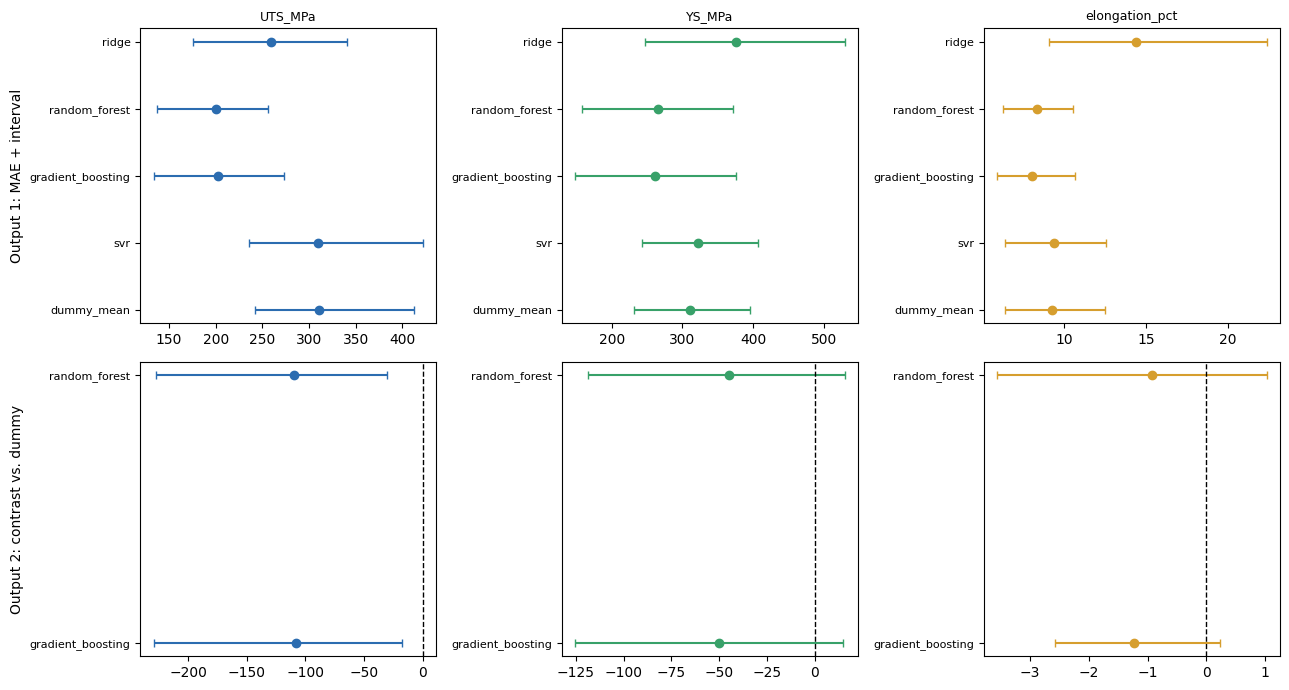

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
target_color = {"UTS_MPa": "#2b6cb0", "YS_MPa": "#38a169", "elongation_pct": "#d69e2e"}

for col_idx, target in enumerate(TARGETS):
    ax = axes[0, col_idx]
    sub = stability_table[stability_table["target"] == target].set_index("model").loc[MODEL_NAMES]
    y_pos = np.arange(len(sub))
    ax.errorbar(sub["MAE"], y_pos,
                xerr=[sub["MAE"] - sub["MAE_ci_lower"], sub["MAE_ci_upper"] - sub["MAE"]],
                fmt="o", color=target_color[target], capsize=3)
    ax.set_yticks(y_pos); ax.set_yticklabels(sub.index, fontsize=8)
    ax.set_title(target, fontsize=9)
    if col_idx == 0:
        ax.set_ylabel("Output 1: MAE + interval")
    ax.invert_yaxis()

for col_idx, target in enumerate(TARGETS):
    ax = axes[1, col_idx]
    sub = contrast_table[contrast_table["target"] == target].set_index("model").loc[["random_forest", "gradient_boosting"]]
    y_pos = np.arange(len(sub))
    ax.errorbar(sub["delta_MAE"], y_pos,
                xerr=[sub["delta_MAE"] - sub["delta_MAE_ci_lower"], sub["delta_MAE_ci_upper"] - sub["delta_MAE"]],
                fmt="o", color=target_color[target], capsize=3)
    ax.axvline(0, color="k", linestyle="--", linewidth=1)
    ax.set_yticks(y_pos); ax.set_yticklabels(sub.index, fontsize=8)
    if col_idx == 0:
        ax.set_ylabel("Output 2: contrast vs. dummy")
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

## Interpretation

UTS_MPa shows a moderate signal. Random Forest (MAE 200.6, 95% CI [136.8, 256.1]) and Gradient Boosting (MAE 203.0, [133.5, 273.7]) both clearly outperform the dummy reference (MAE 310.7, [242.0, 413.1]), and the paired contrast confirms this isn't just non-overlapping marginal intervals: delta_MAE vs. dummy is -110.1 [-226.9, -30.8] for RF and -107.7 [-229.3, -17.5] for GB — both intervals exclude zero, the strongest evidence anywhere in this analysis of a real, if still moderate (R² CI [-0.10, 0.75] for RF), improvement over baseline. Backed by 19 DOI.

YS_MPa shows limited, unstable generalisation. RF's pooled R² CI ([-0.27, 0.27]) straddles zero, and the paired contrast against dummy isn't reliable either: delta_MAE = -45.0 [-118.7, 15.6] for RF and -50.1 [-125.1, 14.9] for GB — both intervals include zero, meaning under DOI-cluster resampling neither model can be said to reliably beat the dummy reference on this target, despite the point estimates favouring the models. It's backed by 20 DOI, more publications than UTS, but the signal itself is weaker and less stable, not just under-supported.

elongation_pct shows marginal performance with substantial small-sample uncertainty. RF's MAE interval (8.34 [6.27, 10.57]) and R² interval ([-0.51, 0.14]) are both wide relative to the point estimate, and the paired contrast against dummy — delta_MAE = -0.93 [-3.56, 1.03] for RF, -1.24 [-2.58, 0.24] for GB — includes zero (or, for GB, nearly touches it). With only 12 DOI backing every interval here, this is the clearest illustration in the whole analysis of why R² and delta-contrast intervals can be genuinely unstable at small publication counts, rather than a modelling failure.

Across all three targets, the ranking by evidentiary strength (UTS > YS > elongation) matches the ranking by DOI count in reverse for YS/elongation but not for UTS vs. YS (19 vs. 20 DOI) — the number of publications alone doesn't determine signal stability; UTS's advantage over dummy is simply larger and more consistent under resampling than YS's, independent of DOI count.


## What these intervals are, and are not

Predictions were fixed by Notebook 03 before any bootstrapping here; nothing was retrained in any replicate, either in this notebook or the one that produced the OOF predictions.

The intervals represent variability under publication-level (DOI-cluster) resampling — how much the pooled metric would move if the literature corpus had sampled a different, similarly-sized set of publications — not per-prediction uncertainty.

They aren't individual prediction intervals: no single row's prediction carries an error bar anywhere in this notebook.

They don't separate epistemic from aleatoric uncertainty — both publication-sampling variability and any genuine measurement/reporting noise in the underlying literature are folded together into one interval.

No interval here is converted into a p-value or a binary significant/not-significant declaration, per the design agreement for this notebook.
